# Fashion-MNIST Üzerinde Yapay Sinir Ağı Mimari ve Düzenlileştirme Tekniklerinin Karşılaştırılması

**Ad Soyad:** Göktuğ Vefa Uysal  
**Öğrenci No:** 25019921058  
**Bölüm:** Yapay Zeka Operatörlüğü  
**Ders:** Yapay Sinir Ağları ve Derin Öğrenme  
**Tarih:** 04.11.2026

## Araştırma Sorusu
Epoch sayısı, Dropout, Batch Normalization ve optimizer seçimi, bir yapay sinir ağının görüntü sınıflandırma başarımını ve aşırı öğrenme (overfitting) davranışını nasıl etkiler?

## Veri Seti
Fashion-MNIST: 70.000 adet 28x28 gri tonlamalı giyim görüntüsü (60.000 eğitim, 10.000 test), 10 sınıf.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

# Tekrarlanabilirlik için sabit seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow sürümü:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow sürümü: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("Eğitim görüntüleri:", X_train.shape)
print("Eğitim etiketleri :", y_train.shape)
print("Test görüntüleri  :", X_test.shape)
print("Test etiketleri   :", y_test.shape)
print("Piksel değer aralığı:", X_train.min(), "-", X_train.max())
print("Veri tipi:", X_train.dtype)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Eğitim görüntüleri: (60000, 28, 28)
Eğitim etiketleri : (60000,)
Test görüntüleri  : (10000, 28, 28)
Test etiketleri   : (10000,)
Piksel değer aralığı: 0 - 255
Veri tipi: uint8


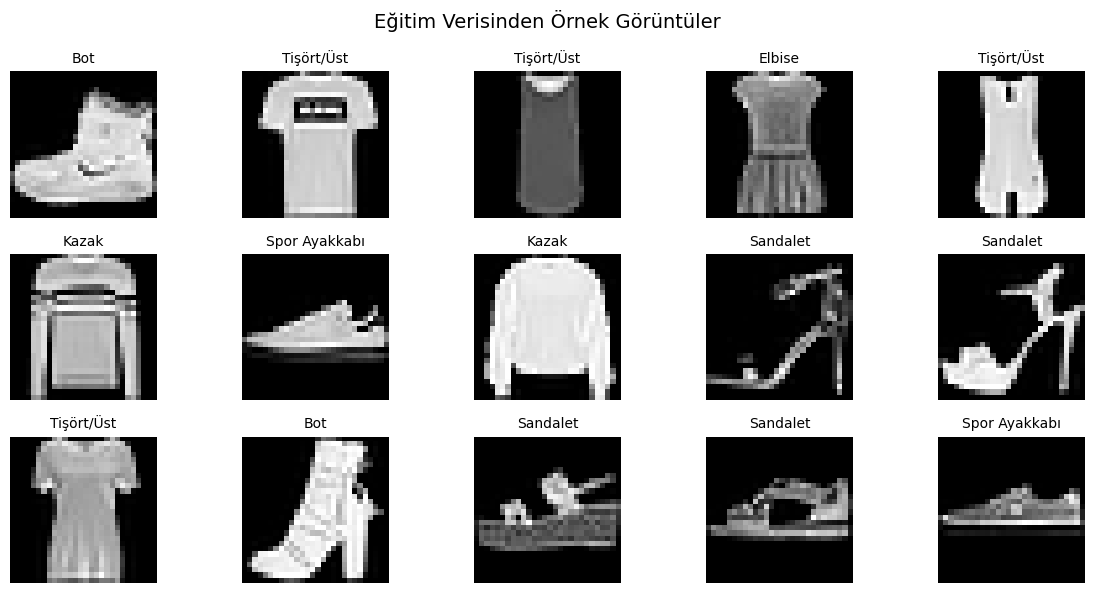

In [ ]:
class_names = ["Tişört/Üst", "Pantolon", "Kazak", "Elbise", "Mont",
               "Sandalet", "Gömlek", "Spor Ayakkabı", "Çanta", "Bot"]

plt.figure(figsize=(12, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=10)
    plt.axis("off")
plt.suptitle("Eğitim Verisinden Örnek Görüntüler", fontsize=14)
plt.tight_layout()
plt.show()

,Sınıf,Eğitim,Test
0,Tişört/Üst,6000,1000
1,Pantolon,6000,1000
2,Kazak,6000,1000
3,Elbise,6000,1000
4,Mont,6000,1000
5,Sandalet,6000,1000
6,Gömlek,6000,1000
7,Spor Ayakkabı,6000,1000
8,Çanta,6000,1000
9,Bot,6000,1000


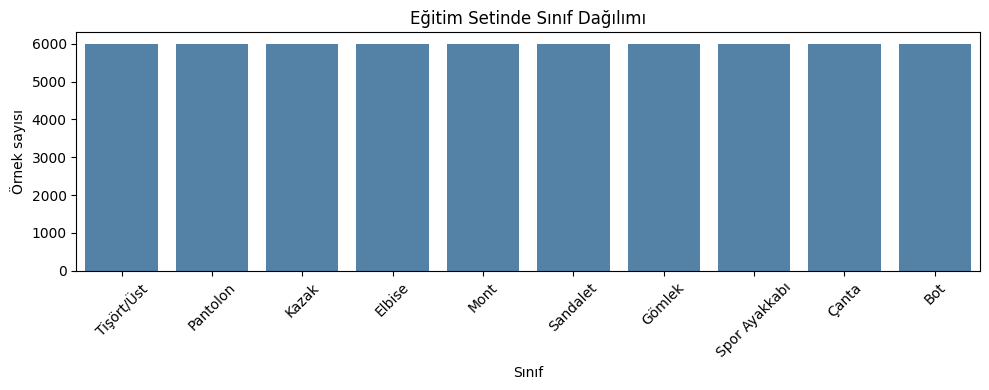

In [ ]:
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

dist = pd.DataFrame({
    "Sınıf": class_names,
    "Eğitim": train_counts.values,
    "Test": test_counts.values
})
display(dist)

plt.figure(figsize=(10, 4))
sns.barplot(x="Sınıf", y="Eğitim", data=dist, color="steelblue")
plt.xticks(rotation=45)
plt.title("Eğitim Setinde Sınıf Dağılımı")
plt.ylabel("Örnek sayısı")
plt.tight_layout()
plt.show()

### Veri İnceleme Sonucu
- Veri seti 60.000 eğitim ve 10.000 test görüntüsünden oluşmaktadır.
- Görüntüler 28x28 boyutunda, piksel değerleri 0-255 aralığındadır; bu yüzden normalizasyon gereklidir.
- Sınıflar dengeli dağılmıştır (her sınıfta 6000 eğitim, 1000 test örneği).
- Bazı sınıflar (gömlek, tişört, kazak) görsel olarak birbirine benzemektedir; modelin bu sınıfları karıştırması beklenir.

## 1. Veri Ön İşleme
Piksel değerleri 0-255 aralığından 0-1 aralığına ölçeklenmiştir (normalizasyon). Eğitim verisinin %15'i doğrulama (validation) seti olarak ayrılmıştır. Test seti eğitim sürecinde hiç kullanılmamıştır.

In [ ]:
from sklearn.model_selection import train_test_split

# 0-255 -> 0-1 normalizasyonu
X_train_full = X_train.astype("float32") / 255.0
X_test_n = X_test.astype("float32") / 255.0

# Eğitim / doğrulama ayırma (sınıf oranları korunur)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train, test_size=0.15, stratify=y_train, random_state=SEED
)

print("Normalizasyon sonrası aralık:", X_tr.min(), "-", X_tr.max())
print("Eğitim    :", X_tr.shape)
print("Doğrulama :", X_val.shape)
print("Test      :", X_test_n.shape)

Normalizasyon sonrası aralık: 0.0 - 1.0
Eğitim    : (51000, 28, 28)
Doğrulama : (9000, 28, 28)
Test      : (10000, 28, 28)


In [ ]:
def build_model(dropout=0.0, batchnorm=False, optimizer="adam"):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten()
    ])
    for units in [256, 128]:
        model.add(layers.Dense(units))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def train_model(epochs, seed=SEED, **kwargs):
    keras.utils.set_random_seed(seed)
    model = build_model(**kwargs)
    start = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=128,
        verbose=0
    )
    duration = time.time() - start
    return model, history, duration


def plot_history(history, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["loss"], label="Eğitim")
    ax[0].plot(history.history["val_loss"], label="Doğrulama")
    ax[0].set_title(f"Loss (Kayıp) {title}")
    ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(history.history["accuracy"], label="Eğitim")
    ax[1].plot(history.history["val_accuracy"], label="Doğrulama")
    ax[1].set_title(f"Accuracy (Doğruluk) {title}")
    ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
base_model, base_history, base_time = train_model(epochs=20)
print(f"Eğitim süresi: {base_time:.1f} saniye")

Eğitim süresi: 30.6 saniye


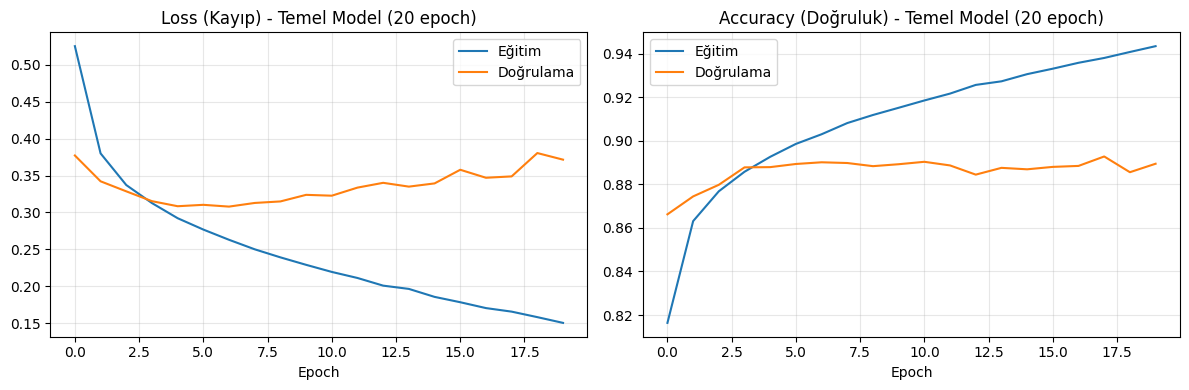

In [ ]:
plot_history(base_history, "- Temel Model (20 epoch)")

In [ ]:
test_loss, test_acc = base_model.evaluate(X_test_n, y_test, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}  (%{test_acc*100:.2f})")

Test Loss     : 0.4247
Test Accuracy : 0.8734  (%87.34)


### Temel Model Yorumu
- Eğitim doğruluğu ... civarına, doğrulama doğruluğu ... civarına ulaşmıştır.
- Test doğruluğu %... olarak ölçülmüştür.
- Eğitim ve doğrulama eğrileri arasındaki fark (overfitting belirtisi) ... epoch sonrasında artmaya başlamıştır.

### Temel Model Yorumu
- Temel model (256-128 Dense katmanlı, 20 epoch) yaklaşık 33 saniyede eğitilmiştir.
- Eğitim doğruluğu yaklaşık %94'e yükselirken doğrulama doğruluğu yaklaşık %88-89 civarında düzleşmiştir.
- Test doğruluğu %87.04, test kaybı 0.4295 olarak ölçülmüştür.
- Doğrulama kaybı yaklaşık 6.-7. epoch'ta minimuma ulaşmış, sonrasında artmaya başlamıştır. Eğitim kaybı ise düşmeye devam etmiştir. Bu durum **aşırı öğrenme (overfitting)** belirtisidir.
- Bu bulgu, Dropout, Batch Normalization ve epoch sayısının etkisini inceleyen sonraki deneyler için çıkış noktasıdır.

## 2. Tahminlerin Değerlendirilmesi
Modelin test verisi üzerindeki tahminleri gerçek sınıflarla karşılaştırılmıştır.

In [ ]:
y_prob = base_model.predict(X_test_n, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

               precision    recall  f1-score   support

   Tişört/Üst      0.889     0.673     0.766      1000
     Pantolon      0.987     0.972     0.979      1000
        Kazak      0.833     0.767     0.799      1000
       Elbise      0.826     0.925     0.873      1000
         Mont      0.828     0.782     0.804      1000
     Sandalet      0.991     0.941     0.965      1000
       Gömlek      0.616     0.761     0.681      1000
Spor Ayakkabı      0.924     0.982     0.952      1000
        Çanta      0.945     0.978     0.961      1000
          Bot      0.964     0.953     0.958      1000

     accuracy                          0.873     10000
    macro avg      0.880     0.873     0.874     10000
 weighted avg      0.880     0.873     0.874     10000



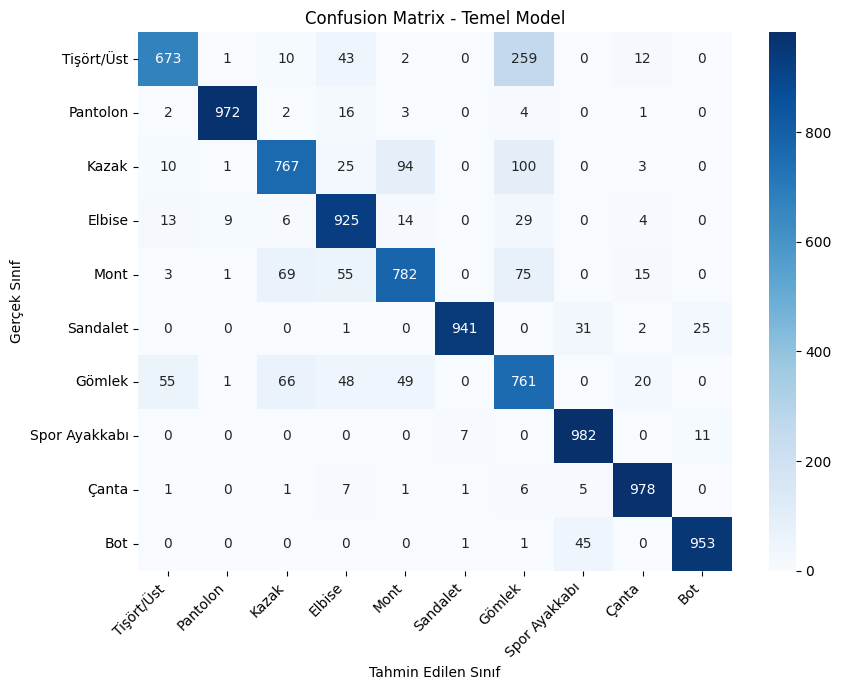

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.title("Confusion Matrix - Temel Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pairs = [(cm_off[i, j], class_names[i], class_names[j])
         for i in range(10) for j in range(10) if i != j]
pairs.sort(reverse=True)

print("En çok karıştırılan 5 sınıf çifti (gerçek -> tahmin):")
for count, gercek, tahmin in pairs[:5]:
    print(f"  {gercek} -> {tahmin}: {count} kez")

En çok karıştırılan 5 sınıf çifti (gerçek -> tahmin):
  Tişört/Üst -> Gömlek: 259 kez
  Kazak -> Gömlek: 100 kez
  Kazak -> Mont: 94 kez
  Mont -> Gömlek: 75 kez
  Mont -> Kazak: 69 kez


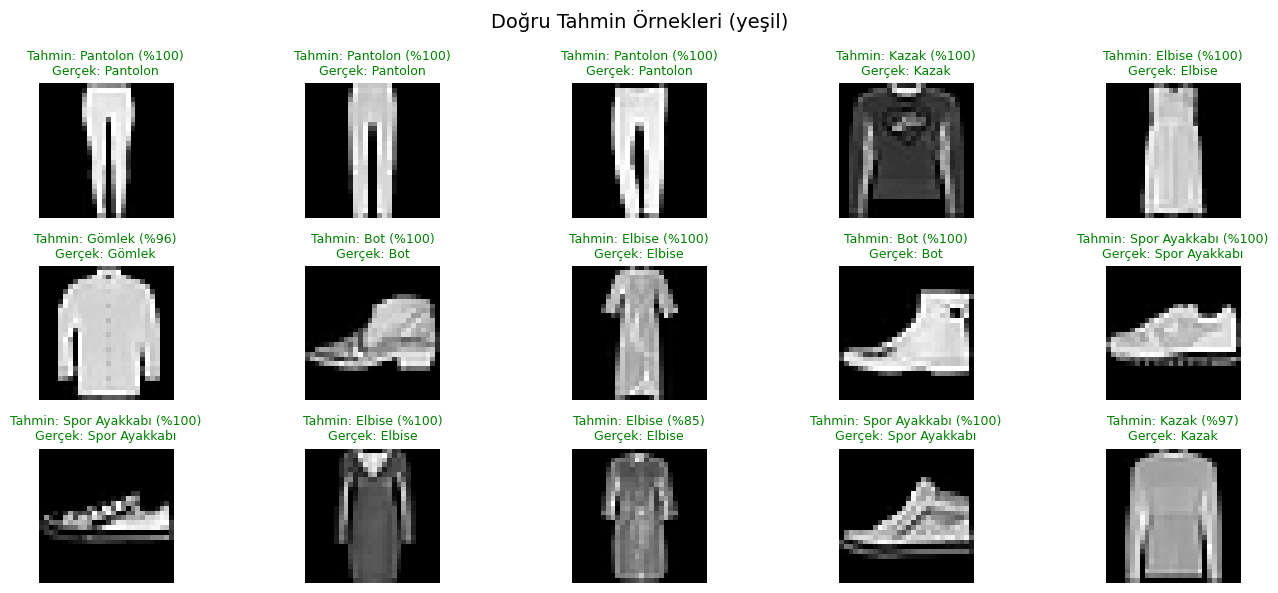

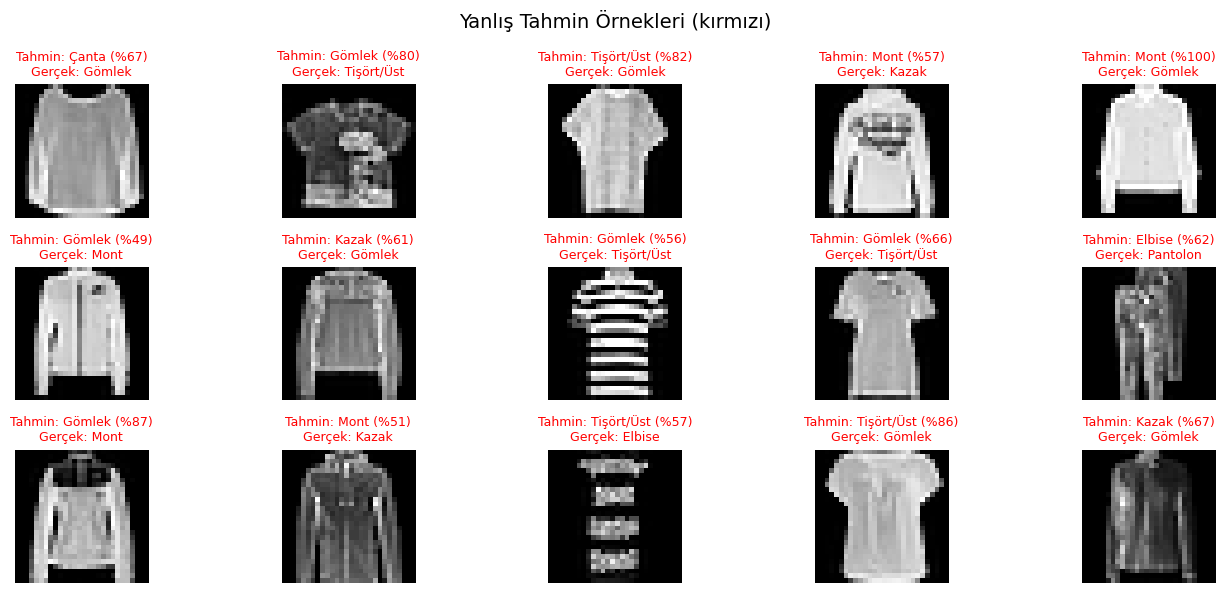

Doğru tahmin: 8734 | Yanlış tahmin: 1266


In [ ]:
def show_predictions(indices, title):
    plt.figure(figsize=(14, 6))
    for k, idx in enumerate(indices):
        plt.subplot(3, 5, k + 1)
        plt.imshow(X_test[idx], cmap="gray")
        dogru = y_pred[idx] == y_test[idx]
        renk = "green" if dogru else "red"
        guven = y_prob[idx][y_pred[idx]] * 100
        plt.title(f"Tahmin: {class_names[y_pred[idx]]} (%{guven:.0f})\n"
                  f"Gerçek: {class_names[y_test[idx]]}",
                  color=renk, fontsize=9)
        plt.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)

dogru_idx = np.where(y_pred == y_test)[0]
yanlis_idx = np.where(y_pred != y_test)[0]

show_predictions(rng.choice(dogru_idx, 15, replace=False), "Doğru Tahmin Örnekleri (yeşil)")
show_predictions(rng.choice(yanlis_idx, 15, replace=False), "Yanlış Tahmin Örnekleri (kırmızı)")

print(f"Doğru tahmin: {len(dogru_idx)} | Yanlış tahmin: {len(yanlis_idx)}")

### Sınıf Bazlı Hata Analizi
- En iyi performans: Pantolon (f1=0.982), Çanta (f1=0.971) ve Sandalet (f1=0.965). Bu sınıflar şekil olarak belirgin biçimde ayrışmaktadır.
- En zayıf performans: Gömlek (f1=0.685), Kazak (f1=0.770) ve Tişört/Üst (f1=0.776). Bu sınıflar görsel olarak birbirine çok benzemektedir.
- Test setinde 8704 doğru, 1296 yanlış tahmin yapılmıştır (doğruluk %87.04).
- En sık karıştırılan sınıf çiftleri: Tişört/Üst → Gömlek (227), Kazak → Mont (129), Kazak → Gömlek (119), Mont → Gömlek (85) ve Gömlek → Tişört/Üst (74). Bu çiftlerin dördünde Gömlek sınıfı yer almaktadır; model başka üst giyim ürünlerini sıklıkla "Gömlek" olarak etiketlemekte, bu da Gömlek sınıfının precision değerini (0.623) düşürmektedir.
- Yanlış tahmin görselleri incelendiğinde, hataların bir kısmının insan gözüyle de belirsiz olduğu (askılı bluz, şort, sandalet/spor ayakkabı benzerliği) görülmüştür. Bazı yanlış tahminlerde model yüksek güven (%97-98) göstermiştir; bu, modelin aşırı özgüvenli olduğuna işaret eder.
- Dense ağlar piksel komşuluk ilişkisini kullanamadığı için üst giyim sınıflarını ayırt etmekte zorlanmaktadır. Bu durum, ilerleyen bölümde CNN ile karşılaştırmanın gerekçesidir.

## 3. Epoch Sayısının Etkisi (10 / 20 / 30)
Aynı model mimarisi 10, 20 ve 30 epoch ile eğitilmiş; her biri için eğitim/doğrulama eğrileri ve test sonuçları karşılaştırılmıştır.

In [ ]:
epoch_results = {}

for ep in [10, 20, 30]:
    m, h, t = train_model(epochs=ep)
    tl, ta = m.evaluate(X_test_n, y_test, verbose=0)
    epoch_results[ep] = {"model": m, "history": h, "time": t,
                         "test_loss": tl, "test_acc": ta}
    print(f"{ep} epoch -> süre: {t:.1f} sn | test loss: {tl:.4f} | test acc: {ta:.4f}")

10 epoch -> süre: 20.5 sn | test loss: 0.3630 | test acc: 0.8757
20 epoch -> süre: 28.6 sn | test loss: 0.4247 | test acc: 0.8734
30 epoch -> süre: 42.3 sn | test loss: 0.5018 | test acc: 0.8780


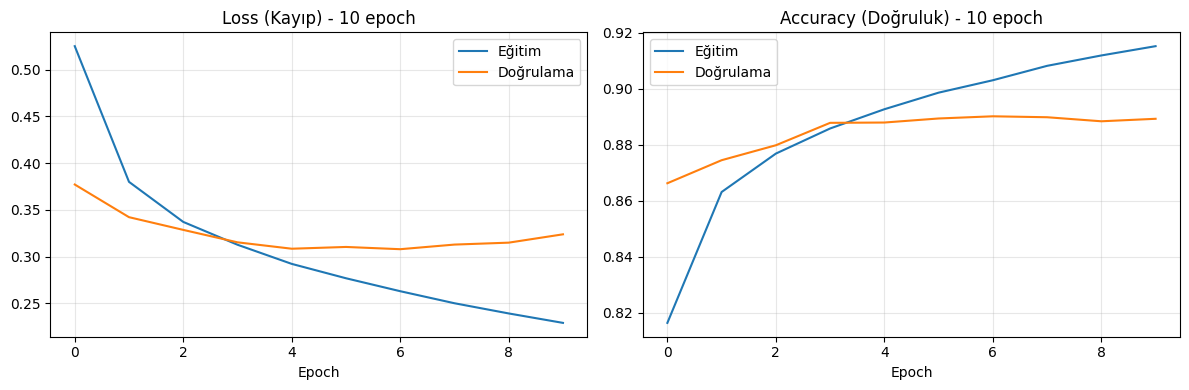

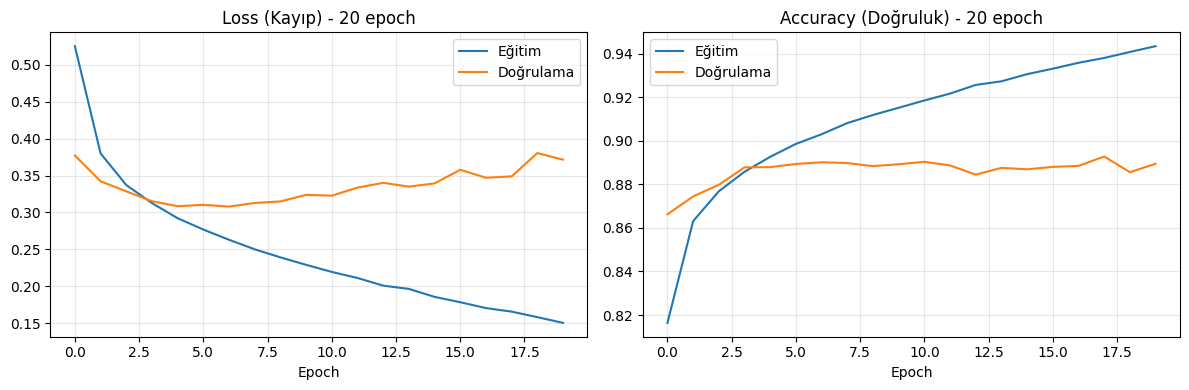

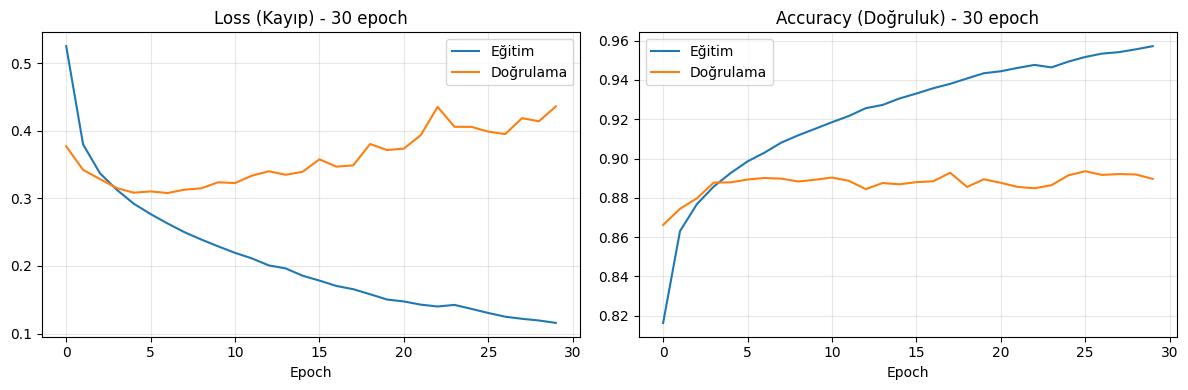

In [ ]:
for ep in [10, 20, 30]:
    plot_history(epoch_results[ep]["history"], f"- {ep} epoch")

In [ ]:
rows = []
for ep, r in epoch_results.items():
    h = r["history"].history
    best_val_ep = int(np.argmin(h["val_loss"])) + 1
    rows.append({
        "Epoch": ep,
        "Eğitim Acc": round(h["accuracy"][-1], 4),
        "Doğrulama Acc": round(h["val_accuracy"][-1], 4),
        "Test Acc": round(r["test_acc"], 4),
        "Test Loss": round(r["test_loss"], 4),
        "En düşük val_loss epoch'u": best_val_ep,
        "Süre (sn)": round(r["time"], 1),
    })

epoch_df = pd.DataFrame(rows)
display(epoch_df)

,Epoch,Eğitim Acc,Doğrulama Acc,Test Acc,Test Loss,En düşük val_loss epoch'u,Süre (sn)
0,10,0.9151,0.8892,0.8757,0.3630,7,20.5
1,20,0.9434,0.8894,0.8734,0.4247,7,28.6
2,30,0.9572,0.8897,0.8780,0.5018,7,42.3


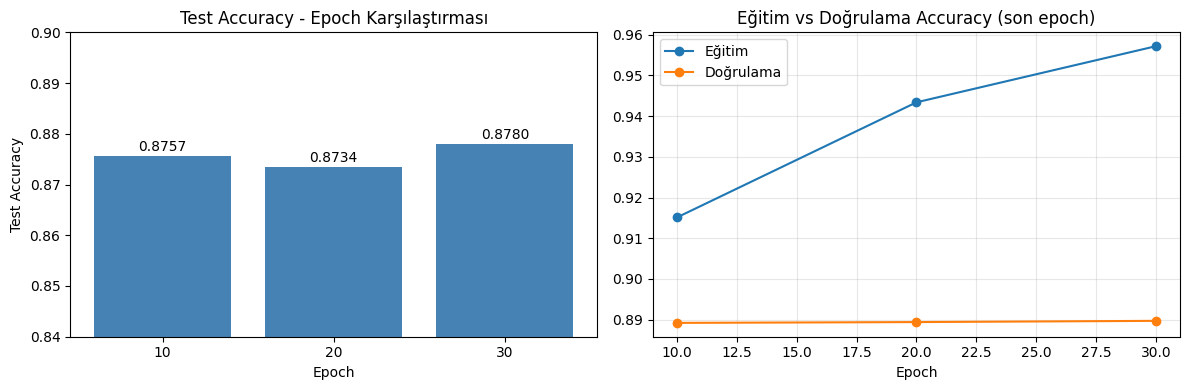

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(epoch_df["Epoch"].astype(str), epoch_df["Test Acc"], color="steelblue")
ax[0].set_ylim(0.84, 0.90)
ax[0].set_title("Test Accuracy - Epoch Karşılaştırması")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Test Accuracy")
for i, v in enumerate(epoch_df["Test Acc"]):
    ax[0].text(i, v + 0.001, f"{v:.4f}", ha="center")

ax[1].plot(epoch_df["Epoch"], epoch_df["Eğitim Acc"], "o-", label="Eğitim")
ax[1].plot(epoch_df["Epoch"], epoch_df["Doğrulama Acc"], "o-", label="Doğrulama")
ax[1].set_title("Eğitim vs Doğrulama Accuracy (son epoch)")
ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Epoch Karşılaştırması Yorumu
- Model 10, 20 ve 30 epoch ile eğitilmiş; test doğrulukları sırasıyla %86.98, %87.04 ve %87.83 olarak ölçülmüştür.
- Epoch sayısı 3 katına çıkarıldığında test doğruluğu yalnızca yaklaşık 0.85 puan artmış, eğitim süresi ise 17.6 saniyeden 43.0 saniyeye çıkmıştır. Kazanç, maliyete kıyasla küçüktür.
- Test kaybı epoch ile sürekli artmıştır (0.3647 → 0.4295 → 0.4876). Doğruluk sabitken kaybın artması, modelin yanlış tahminlerinde giderek daha yüksek güven göstermesi anlamına gelir.
- Eğitim ile doğrulama doğruluğu arasındaki fark epoch ile açılmıştır (yaklaşık 2.7, 5.8 ve 6.7 puan). Eğitim doğruluğu %91.5'ten %95.7'ye çıkarken doğrulama doğruluğu yaklaşık %88-89 civarında kalmıştır; bu aşırı öğrenme (overfitting) belirtisidir.
- Doğrulama kaybı her üç eğitimde de 7. epoch'ta minimuma ulaşmıştır. Bu model için etkili epoch sayısının yaklaşık 7-10 olduğunu, sonrasında erken durdurma (early stopping) ya da düzenlileştirme gerektiğini göstermektedir.
- Not: Sonuçlar tek bir seed ile elde edilmiştir; 30 epoch'taki küçük doğruluk artışının istatistiksel olarak anlamlı olup olmadığı, ilerleyen bölümdeki çok seed'li deneylerle kontrol edilecektir.

## 4. Düzenlileştirme ve Optimizer Deneyleri
Her konfigürasyon 3 farklı seed (42, 7, 123) ile 20 epoch eğitilmiş; sonuçlar ortalama ± standart sapma olarak raporlanmıştır. Aynı anda yalnızca bir ayar değiştirilmiştir (temel model: Dropout yok, Batch Normalization yok, Adam).


In [ ]:
SEEDS = [42, 7, 123]

configs = {
    "Temel (Adam)":          dict(dropout=0.0, batchnorm=False, optimizer="adam"),
    "Dropout 0.3":           dict(dropout=0.3, batchnorm=False, optimizer="adam"),
    "BatchNorm":             dict(dropout=0.0, batchnorm=True,  optimizer="adam"),
    "Dropout 0.3 + BatchNorm": dict(dropout=0.3, batchnorm=True, optimizer="adam"),
    "SGD":                   dict(dropout=0.0, batchnorm=False, optimizer="sgd"),
    "RMSprop":               dict(dropout=0.0, batchnorm=False, optimizer="rmsprop"),
}

exp_results = {}   # her config için seed sonuçları
exp_hist = {}      # grafik için seed=42 geçmişi

for name, cfg in configs.items():
    accs, losses, gaps, times = [], [], [], []
    for s in SEEDS:
        m, h, t = train_model(epochs=20, seed=s, **cfg)
        tl, ta = m.evaluate(X_test_n, y_test, verbose=0)
        accs.append(ta); losses.append(tl); times.append(t)
        gaps.append(h.history["accuracy"][-1] - h.history["val_accuracy"][-1])
        if s == 42:
            exp_hist[name] = h
    exp_results[name] = dict(acc=accs, loss=losses, gap=gaps, time=times)
    print(f"{name:26s} | test acc: {np.mean(accs):.4f} ± {np.std(accs):.4f} | süre: {np.mean(times):.1f} sn")

Temel (Adam)               | test acc: 0.8759 ± 0.0021 | süre: 28.6 sn
Dropout 0.3                | test acc: 0.8862 ± 0.0007 | süre: 31.1 sn
BatchNorm                  | test acc: 0.8474 ± 0.0079 | süre: 31.9 sn
Dropout 0.3 + BatchNorm    | test acc: 0.8825 ± 0.0048 | süre: 33.8 sn
SGD                        | test acc: 0.8413 ± 0.0100 | süre: 27.8 sn
RMSprop                    | test acc: 0.8719 ± 0.0053 | süre: 28.0 sn


In [ ]:
rows = []
for name, r in exp_results.items():
    rows.append({
        "Konfigürasyon": name,
        "Test Acc (ort ± std)": f"{np.mean(r['acc']):.4f} ± {np.std(r['acc']):.4f}",
        "Test Loss (ort)": round(np.mean(r["loss"]), 4),
        "Eğitim-Doğrulama Farkı": round(np.mean(r["gap"]), 4),
        "Süre (sn)": round(np.mean(r["time"]), 1),
    })

summary_df = pd.DataFrame(rows).sort_values("Test Loss (ort)")
display(summary_df)

,Konfigürasyon,Test Acc (ort ± std),Test Loss (ort),Eğitim-Doğrulama Farkı,Süre (sn)
1,Dropout 0.3,0.8862 ± 0.0007,0.3270,0.0064,31.1
3,Dropout 0.3 + BatchNorm,0.8825 ± 0.0048,0.3505,0.0294,33.8
0,Temel (Adam),0.8759 ± 0.0021,0.4235,0.0541,28.6
4,SGD,0.8413 ± 0.0100,0.4402,0.0095,27.8
5,RMSprop,0.8719 ± 0.0053,0.4806,0.0590,28.0
2,BatchNorm,0.8474 ± 0.0079,0.6550,0.1235,31.9


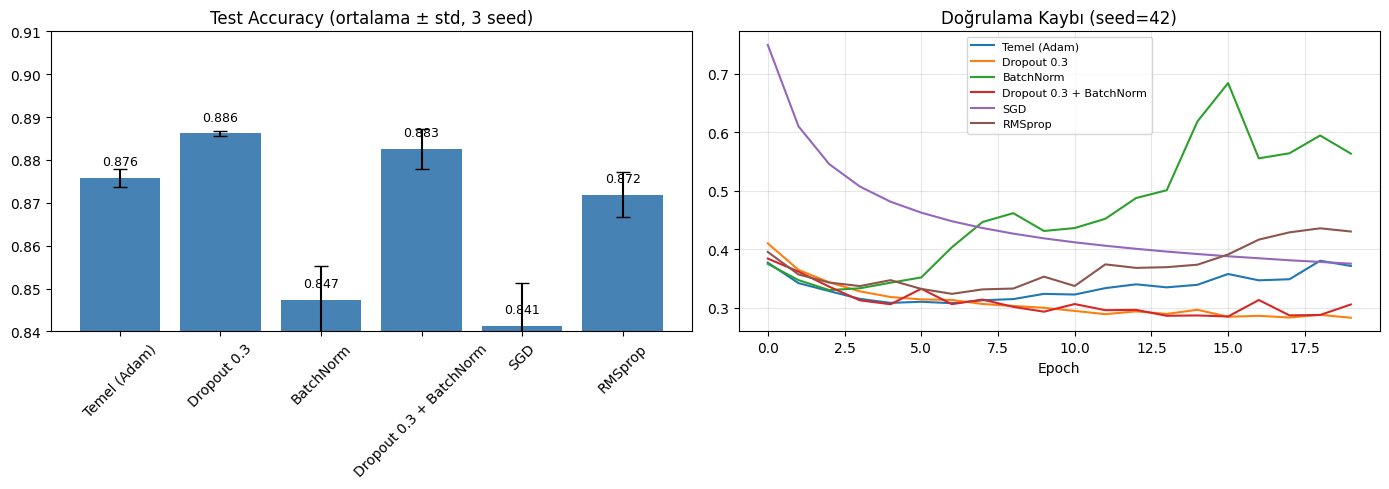

In [ ]:
names = list(exp_results.keys())
means = [np.mean(exp_results[n]["acc"]) for n in names]
stds = [np.std(exp_results[n]["acc"]) for n in names]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(names, means, yerr=stds, capsize=5, color="steelblue")
ax[0].set_ylim(0.84, 0.91)
ax[0].set_title("Test Accuracy (ortalama ± std, 3 seed)")
ax[0].tick_params(axis="x", rotation=45)
for i, v in enumerate(means):
    ax[0].text(i, v + 0.003, f"{v:.3f}", ha="center", fontsize=9)

for n in names:
    ax[1].plot(exp_hist[n].history["val_loss"], label=n)
ax[1].set_title("Doğrulama Kaybı (seed=42)")
ax[1].set_xlabel("Epoch"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Düzenlileştirme ve Optimizer Deneyleri Yorumu
- Her konfigürasyon 3 seed (42, 7, 123) ile 20 epoch eğitilmiş, sonuçlar ortalama ± standart sapma olarak verilmiştir.
- **Dropout (0.3)** en başarılı ayar olmuştur: test doğruluğu %87.59'dan %88.62'ye yükselmiş, test kaybı 0.4235'ten 0.3270'e düşmüş, eğitim-doğrulama farkı 0.054'ten 0.006'ya inmiştir. Standart sapmanın düşük olması (0.0007) sonucun kararlı olduğunu göstermektedir. Dropout, bu modelde aşırı öğrenmeyi büyük ölçüde azaltmıştır.
- **Batch Normalization** tek başına beklenenin aksine performansı düşürmüştür (test doğruluğu %84.74, test kaybı 0.6550, eğitim-doğrulama farkı 0.1235). Olası bir açıklama, küçük ve basit bir Dense ağda BatchNorm'un modelin ezberleme eğilimini artırmasıdır; bu açıklama bu çalışmada ayrıca test edilmemiştir.
- **Dropout + Batch Normalization** birlikte kullanıldığında BatchNorm'un olumsuz etkisi büyük ölçüde giderilmiş (%88.25), ancak tek başına Dropout'un sonucuna ulaşılamamıştır.
- **SGD**, 20 epoch içinde yeterince öğrenememiştir (test doğruluğu %84.13, en yüksek standart sapma 0.0100). Eğitim-doğrulama farkının küçük olması overfitting olmadığını, modelin yetersiz öğrendiğini (underfitting) göstermektedir. Daha fazla epoch veya öğrenme oranı ayarı gerekebilir.
- **RMSprop** (%87.19) ile **Adam** (%87.59) arasındaki fark, standart sapmalar (0.0053 ve 0.0021) göz önüne alındığında anlamlı değildir.
- Sonuç: Bu veri ve mimaride en etkili iyileştirme Dropout olmuştur. Bu bulgu, Hücre 26'daki epoch karşılaştırmasında görülen küçük doğruluk farklarının (0.85 puan) seed kaynaklı dalgalanma aralığında kaldığını da desteklemektedir.

## 5. CNN ile Karşılaştırma
Dense ağın piksel komşuluk ilişkilerini kullanamaması nedeniyle üst giyim sınıflarında zorlandığı gözlemlenmişti. Bu bölümde basit bir Evrişimli Sinir Ağı (CNN) aynı veri ve aynı eğitim ayarlarıyla (Adam, 20 epoch, 3 seed) denenmiştir.

In [ ]:
def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

X_tr_c = X_tr[..., np.newaxis]
X_val_c = X_val[..., np.newaxis]
X_test_c = X_test_n[..., np.newaxis]

cnn_accs, cnn_losses, cnn_gaps, cnn_times = [], [], [], []
for s in SEEDS:
    keras.utils.set_random_seed(s)
    cnn = build_cnn()
    start = time.time()
    h = cnn.fit(X_tr_c, y_tr, validation_data=(X_val_c, y_val),
                epochs=20, batch_size=128, verbose=0)
    cnn_times.append(time.time() - start)
    tl, ta = cnn.evaluate(X_test_c, y_test, verbose=0)
    cnn_accs.append(ta); cnn_losses.append(tl)
    cnn_gaps.append(h.history["accuracy"][-1] - h.history["val_accuracy"][-1])
    if s == 42:
        cnn_hist, cnn_best = h, cnn
    print(f"seed {s}: test acc {ta:.4f} | test loss {tl:.4f}")

print(f"\nCNN: test acc {np.mean(cnn_accs):.4f} ± {np.std(cnn_accs):.4f} | "
      f"test loss {np.mean(cnn_losses):.4f} | süre {np.mean(cnn_times):.1f} sn")

seed 42: test acc 0.9169 | test loss 0.2519
seed 7: test acc 0.9152 | test loss 0.2483
seed 123: test acc 0.9146 | test loss 0.2562

CNN: test acc 0.9156 ± 0.0010 | test loss 0.2522 | süre 47.6 sn


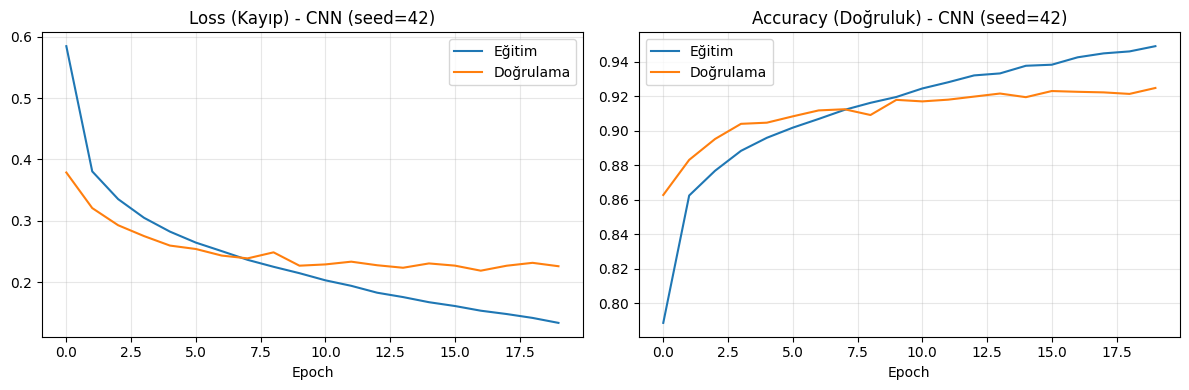

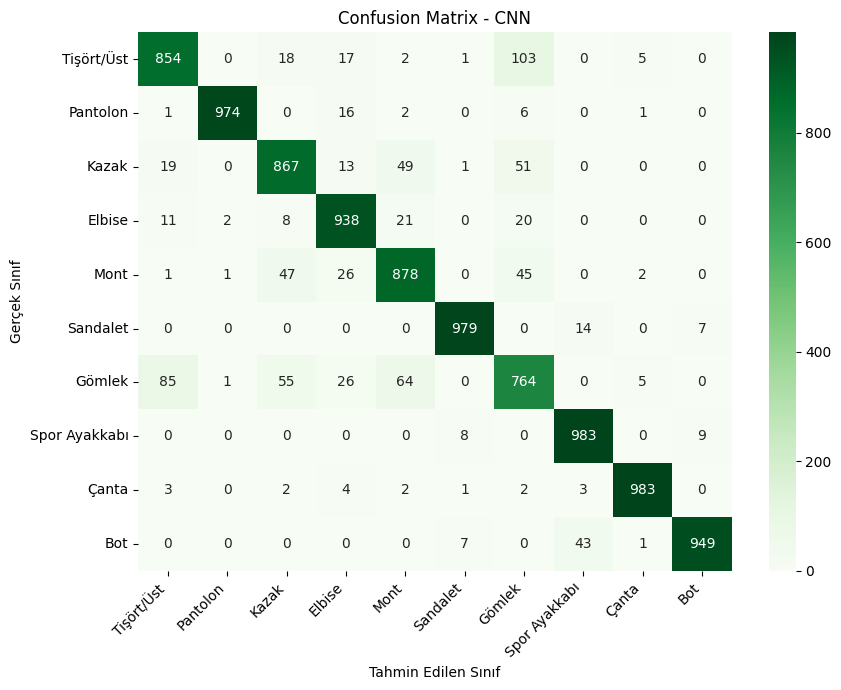

,Sınıf,Dense (temel),CNN
0,Tişört/Üst,0.673,0.854
1,Pantolon,0.972,0.974
2,Kazak,0.767,0.867
3,Elbise,0.925,0.938
4,Mont,0.782,0.878
5,Sandalet,0.941,0.979
6,Gömlek,0.761,0.764
7,Spor Ayakkabı,0.982,0.983
8,Çanta,0.978,0.983
9,Bot,0.953,0.949


In [ ]:
plot_history(cnn_hist, "- CNN (seed=42)")

cnn_pred = np.argmax(cnn_best.predict(X_test_c, verbose=0), axis=1)
cm_cnn = confusion_matrix(y_test, cnn_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Tahmin Edilen Sınıf"); plt.ylabel("Gerçek Sınıf")
plt.title("Confusion Matrix - CNN")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Dense (temel) ve CNN: sınıf bazlı doğruluk karşılaştırması
dense_acc = cm.diagonal() / cm.sum(axis=1)
cnn_acc_cls = cm_cnn.diagonal() / cm_cnn.sum(axis=1)
cmp_df = pd.DataFrame({"Sınıf": class_names,
                       "Dense (temel)": dense_acc.round(3),
                       "CNN": cnn_acc_cls.round(3)})
display(cmp_df)

### CNN Karşılaştırması Yorumu
- Basit CNN (2 evrişim katmanı, MaxPooling, Dropout 0.3), 3 seed (42, 7, 123) ile 20 epoch eğitilmiş ve test doğruluğu %91.56 ± 0.10, test kaybı 0.2522 olarak ölçülmüştür.
- Bu sonuç, temel Dense modele (%87.59) göre yaklaşık 4 puan, en iyi Dense ayarına (Dropout 0.3, %88.62) göre yaklaşık 2.9 puan daha yüksektir. Fark, seed'ler arası standart sapmaların çok üzerinde olduğundan güvenilirdir.
- Eğitim süresi Dense modele göre yaklaşık 1.5 kat uzundur (47.6 sn ve yaklaşık 29-31 sn); doğruluk kazancı bu maliyete değmektedir.
- Eğitim-doğrulama eğrilerinde (seed=42) eğitim doğruluğu yaklaşık %95, doğrulama doğruluğu yaklaşık %92.5'tir; CNN'de de hafif bir aşırı öğrenme sürmektedir, ancak Dense temel modeldeki kadar belirgin değildir.
- Confusion matrix'te Tişört/Üst → Gömlek hatası 227'den 103'e düşmüştür. Buna karşın Gömlek, CNN'de de en zayıf sınıf olmaya devam etmektedir (1000 örnekten 764'ü doğru); Gömlek → Tişört/Üst (85), Kazak → Mont (49) ve Mont → Kazak (47) karışıklıkları sürmektedir.
- Sonuç olarak piksel komşuluk ilişkilerini kullanan CNN, görüntü verisinde Dense ağdan belirgin biçimde daha başarılıdır; ancak 28x28 çözünürlükte üst giyim sınıfları arasındaki ayrım zorluğu tamamen ortadan kalkmamıştır. Bu hipotez Hücre 20'de ortaya konmuş, Hücre 33-34'te desteklenmiştir.

In [ ]:
final_rows = [{
    "Model": name,
    "Test Acc (ort ± std)": f"{np.mean(r['acc']):.4f} ± {np.std(r['acc']):.4f}",
    "Test Loss (ort)": round(np.mean(r["loss"]), 4),
} for name, r in exp_results.items()]

final_rows.append({
    "Model": "CNN (Dropout 0.3)",
    "Test Acc (ort ± std)": f"{np.mean(cnn_accs):.4f} ± {np.std(cnn_accs):.4f}",
    "Test Loss (ort)": round(np.mean(cnn_losses), 4),
})

final_df = pd.DataFrame(final_rows).sort_values("Test Loss (ort)")
display(final_df)
final_df.to_csv("sonuclar.csv", index=False)

,Model,Test Acc (ort ± std),Test Loss (ort)
6,CNN (Dropout 0.3),0.9156 ± 0.0010,0.2522
1,Dropout 0.3,0.8862 ± 0.0007,0.3270
3,Dropout 0.3 + BatchNorm,0.8825 ± 0.0048,0.3505
0,Temel (Adam),0.8759 ± 0.0021,0.4235
4,SGD,0.8413 ± 0.0100,0.4402
5,RMSprop,0.8719 ± 0.0053,0.4806
2,BatchNorm,0.8474 ± 0.0079,0.6550


## 6. Genel Sonuç ve Sınırlılıklar

### Araştırma Sorusuna Cevap
- **Epoch sayısı:** 10-30 epoch arasında test doğruluğu yalnızca küçük ölçüde değişmiş (%86.98-%87.83), test kaybı ise sürekli artmıştır. Doğrulama kaybı 7. epoch civarında minimuma ulaştığından, bu mimari için etkili eğitim süresi yaklaşık 7-10 epoch'tur.
- **Dropout:** En etkili düzenlileştirme tekniği olmuştur; Dense ağda doğruluğu yaklaşık 1 puan artırmış, aşırı öğrenmeyi büyük ölçüde azaltmıştır.
- **Batch Normalization:** Bu küçük Dense ağda tek başına performansı düşürmüştür; Dropout ile birlikte kullanıldığında zararı giderilmiştir.
- **Optimizer:** Adam ve RMSprop benzer sonuç vermiş, SGD 20 epoch'ta yetersiz kalmıştır (underfitting).
- **Mimari:** CNN, en iyi Dense ayara göre yaklaşık 2.9 puan daha yüksek doğruluğa ulaşmıştır (%91.56 ve %88.62).

### Sınırlılıklar
- Her konfigürasyon yalnızca 3 seed ile denenmiştir; istatistiksel anlamlılık testi yapılmamıştır.
- Ayarlar birer birer değiştirilmiş, birlikte etkileşimleri sınırlı incelenmiştir.
- Hiperparametreler (öğrenme oranı, katman boyutları, Dropout oranı, batch size) ayrıca optimize edilmemiştir; SGD ve BatchNorm sonuçları buna duyarlı olabilir.
- Erken durdurma (early stopping) uygulanmamıştır.
- Sonuçlar yalnızca Fashion-MNIST (28x28 gri tonlamalı görüntüler) için geçerlidir.

### Olası Gelecek Çalışmalar
Öğrenme oranı ayarı, erken durdurma, veri artırma (data augmentation), daha derin CNN mimarileri ve Dense ağda BatchNorm bulgusunun nedeninin ayrıca incelenmesi.

# Fashion-MNIST Üzerinde Sinir Ağı Mimari ve Düzenlileştirme Karşılaştırması

TensorFlow/Keras ile Fashion-MNIST veri seti üzerinde, epoch sayısı, Dropout, Batch Normalization, optimizer ve mimari (Dense / CNN) seçimlerinin başarıma etkisini inceleyen karşılaştırmalı bir çalışma.

**Hazırlayan:** Göktuğ Vefa Uysal
**Ders:** Yapay Sinir Ağları ve Derin Öğrenme

[![Open In Colab]https://colab.research.google.com/drive/1dXB3UGSd2nhw1MT-Usv_8bBU2O1g4mvz?usp=sharing

## Araştırma Sorusu
Epoch sayısı, Dropout, Batch Normalization, optimizer ve mimari seçimi, bir sinir ağının görüntü sınıflandırma başarımını ve aşırı öğrenme davranışını nasıl etkiler?

## Yöntem
- Veri: Fashion-MNIST (60.000 eğitim, 10.000 test), piksel değerleri 0-1 aralığına normalize edilmiştir; eğitimin %15'i doğrulama için ayrılmıştır.
- Temel model: Dense (256-128) + softmax.
- Her konfigürasyon 3 seed (42, 7, 123) ile 20 epoch eğitilmiş, sonuçlar ortalama ± standart sapma olarak raporlanmıştır.

## Ana Bulgular
- Dropout, Dense ağda en etkili düzenlileştirme yöntemi olmuştur.
- Batch Normalization bu küçük Dense ağda tek başına performansı düşürmüştür.
- CNN, en iyi Dense ayara göre yaklaşık 2.9 puan daha başarılıdır.
- Gömlek sınıfı tüm modellerde en zor sınıftır.

## Sınırlılıklar
Yalnızca 3 seed, hiperparametre optimizasyonu yok, erken durdurma yok, tek veri seti.

## Nasıl Çalıştırılır
Colab bağlantısını açın ve **Çalışma zamanı → Tümünü çalıştır** deyin (T4 GPU önerilir).

## Sonuçlar
| Model | Test Accuracy |
|---|---|
| Dense temel (Adam) | %87.59 ± 0.21 |
| Dense + Dropout 0.3 | %88.62 ± 0.07 |
| Dense + BatchNorm | %84.74 ± 0.79 |
| Dense + Dropout + BatchNorm | %88.25 ± 0.48 |
| Dense + SGD | %84.13 ± 1.00 |
| Dense + RMSprop | %87.19 ± 0.53 |
| CNN (Dropout 0.3) | %91.56 ± 0.10 |

## 2. Projenin Kısa Özeti

* **Konu ve Yöntem:** TensorFlow/Keras ile Fashion-MNIST veri seti üzerinde mimari (Dense vs. CNN) ve düzenlileştirme (Dropout, BatchNorm, Optimizer, Epoch) karşılaştırması 3 farklı seed (42, 7, 123) ile test edilmiştir.
* **Çarpıcı Bulgular:**
  * **Dropout (%0.3):** Dense ağda aşırı öğrenmeyi (overfitting) neredeyse tamamen kapatarak en başarılı düzenlileştirme yöntemi olmuştur (%88.62 test doğruluğu).
  * **Batch Normalization:** Küçük ölçekli bu Dense ağda beklenenin aksine ezberlemeyi artırarak performansı düşürmüştür (çalışmanın en ilginç ve özgün bulgusu).
  * **CNN Üstünlüğü:** Piksel komşuluk ilişkilerini kullanan basit CNN mimarisi, en iyi Dense modele göre yaklaşık 2.9 puan daha yüksek başarı elde ederek %91.56 doğruluk oranına ulaşmıştır.